Suppose we start with $N$ individuals. Each individual has an independent lifetime

$$
X_i\sim\operatorname{Exp}(\mu).
$$

The probability that individual $i$ survives until time $t$ is

$$
P(X_i>t)=e^{-\mu t}.
$$

Define the random variable

$$
Y_t=\sum_{i=1}^{N}\mathbf{1}_{\{X_i>t\}}.
$$

Since each indicator is an independent Bernoulli random variable with success probability $(e^{-\mu t})$,

$$
\boxed{Y_t\sim\operatorname{Binomial}(N,e^{-\mu t})}.
$$


$$
P(Y_t=k)=\binom Nk(e^{-\mu t})^k(1-e^{-\mu t})^{N-k}
$$

Consequently,

$$
E[Y_t]=Ne^{-\mu t}.
$$

-----

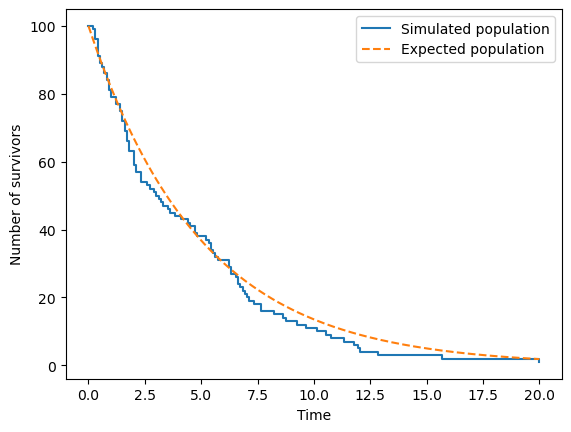

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Model parameters
N = 100
mu = 0.2

# Generate independent lifetimes
rng = np.random.default_rng(42)
lifetimes = rng.exponential(scale=1/mu, size=N) # records each individuals life time

# Count survivors at each time
times = np.linspace(0, 20, 200)
Y = np.array([
    np.sum(lifetimes > t)
    for t in times
])

# Theoretical expected population
expected_Y = N * np.exp(-mu * times)

plt.step(times, Y, where="post", label="Simulated population")
plt.plot(times, expected_Y, "--", label="Expected population")

plt.xlabel("Time")
plt.ylabel("Number of survivors")
plt.legend()
plt.show()
